# Training sequence-to-function models for chromatin accessibility using CREsted

In this introductory notebook, we will train a sequence-to-function model on mouse cortex data. Sequence-to-function models are commonly used to study gene regulation and to understand the underlying regulatory codes governing enhancer activity and gene expression. Here, we will train a convolutional neural network (CNN) that will take a short DNA sequence as input and try to predict cell type specific chromation accessibility (for example scATAC-seq data). For our CNN to be able to accomplish this task, it will have to learn the important sequence features (such as TF binding sites, their placing and orientation etc.) of cis-regulatory elements (CREs). After a model is trained, we can use that model in many applications. The first step is usually to 'explain' the model, i.e. ask that model 'How did you make that specific prediction?' to extract the features that the model has learned. This is how we figure out how enhancers and other CREs work. We can also use these models for other downstream tasks, such as designing synthetic enhancers or discovering the regulatory effects of SNPs.

To train these models, we will use a python package called CREsted. The specific type of model we are training is called a 'peak regression' model. This naming is due to how we preprocess our data. In a 'peak regression' model, we have a set of peaks, and each peak has a accessibility value that the model tries to predict. So it's a regression task on peaks, therefore 'peak regression'. Another common way is to binarize our peaks, so they are either accessible (1) in a specific cell type or not accessible (0). This type of model is called a clasification model, since we are trying to classify whether a peak is accessible or not accessible in each of our cell types. 

This tutorial is an minimally adapted version of a tutorial on the CREsted documentation (https://crested.readthedocs.io), I highly suggest that you check out the rest of the stuff on CREsted documentation if you want to see what else is there to do with your model.

In [1]:
# Set package settings
import matplotlib
import os

## Set the font type to ensure text is saved as whole words
matplotlib.rcParams["pdf.fonttype"] = 42
matplotlib.rcParams["ps.fonttype"] = 42

## You can set the base directory for data retrieval with crested.get_dataset()/get_model()
os.environ['CRESTED_DATA_DIR'] = '../'
os.environ['LD_LIBRARY_PATH'] = '/data/groups/vib.ai/stein.aerts/eceksi/package_managers/conda_envs/crested_261104/lib/python3.13/site-packages/nvidia/cublas/lib:/data/groups/vib.ai/stein.aerts/eceksi/package_managers/conda_envs/crested_261104/lib/python3.13/site-packages/nvidia/cuda_cupti/lib:/data/groups/vib.ai/stein.aerts/eceksi/package_managers/conda_envs/crested_261104/lib/python3.13/site-packages/nvidia/cuda_nvrtc/lib:/data/groups/vib.ai/stein.aerts/eceksi/package_managers/conda_envs/crested_261104/lib/python3.13/site-packages/nvidia/cuda_runtime/lib:/data/groups/vib.ai/stein.aerts/eceksi/package_managers/conda_envs/crested_261104/lib/python3.13/site-packages/nvidia/cudnn/lib:/data/groups/vib.ai/stein.aerts/eceksi/package_managers/conda_envs/crested_261104/lib/python3.13/site-packages/nvidia/cufft/lib:/data/groups/vib.ai/stein.aerts/eceksi/package_managers/conda_envs/crested_261104/lib/python3.13/site-packages/nvidia/curand/lib:/data/groups/vib.ai/stein.aerts/eceksi/package_managers/conda_envs/crested_261104/lib/python3.13/site-packages/nvidia/cusolver/lib:/data/groups/vib.ai/stein.aerts/eceksi/package_managers/conda_envs/crested_261104/lib/python3.13/site-packages/nvidia/cusparse/lib:/data/groups/vib.ai/stein.aerts/eceksi/package_managers/conda_envs/crested_261104/lib/python3.13/site-packages/nvidia/nccl/lib:/data/groups/vib.ai/stein.aerts/eceksi/package_managers/conda_envs/crested_261104/lib/python3.13/site-packages/nvidia/nvjitlink/lib:'


## Importing data

For this tutorial, we will use the mouse BICCN dataset which is available in the {func}`~crested.get_dataset` function.  
To train a CREsted peak regression model on your data, you need: 
1. A consensus regions BED file containing all the regions of interest across cell types.
2. A folder containing the bigwig files per cell type, or a list of bigwig files.
3. A genome fasta file and optionally a chromosome sizes file.

You could use a tool like SnapATAC2 or pycisTopic to generate the consensus regions and bigwig files from your own data.

In [ ]:
import anndata as ad
import crested
import numpy as np
import matplotlib.pyplot as plt
import keras

/data/groups/vib.ai/stein.aerts/eceksi/package_managers/conda_envs/crested_261104/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
I0000 00:00:1793877348.871474 2886529 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793877348.915318 2886529 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793877349.93023

In [7]:
# This is to check if your tensforflow can find your gpu, if not, you might need to check your installation
# Make sure CUDA and cuDNN are installed correctly and that your GPU drivers are up to date.
# If they are, one common cause is that your LD_LIBRARY_PATH isn't set correctly. 
# It should be set to the path that your correct CUDA and cuDNN libraries are located in. 
# You can check this by running `echo $LD_LIBRARY_PATH` in your terminal.
import tensorflow as tf
print(tf.__version__)
print(tf.config.list_physical_devices('GPU'))
print(tf.sysconfig.get_build_info())

2.21.0
[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
OrderedDict({'cpu_compiler': 'clang', 'cuda_compute_capabilities': ['sm_60', 'sm_70', 'sm_80', 'sm_89', 'compute_90'], 'cuda_version': '12.5.1', 'cudnn_version': '9', 'is_cuda_build': True, 'is_rocm_build': False, 'is_tensorrt_build': False})


By loading our genome in the {class}`crested.Genome` class and setting it with {func}`~crested.register_genome`, the genome is automatically used in all functions throughout CREsted. If you don't provide the chromomsome sizes, they will be automatically calculated from the fasta.  
:::{note}
Any function or class that expects a genome object can still accept a genome object as explicit input even if one was already registered. In that case, the input will be used instead of the registered genome. 
:::

In [12]:
## Set the genome paths
genome = crested.Genome("./resources/mm10.fa", "./resources/mm10.chrom.sizes") # pyright: ignore[reportArgumentType]
crested.register_genome(genome)  # Register the genome so that it's automatically used in every function

# If you want to get the sequnce of a specific genomic
print(genome.fetch("chr1", 10000000, 10000010))

2026-11-05T12:18:48.196387+0100 INFO Genome mm10 registered.
TTTTCAATGC


For this tutorial we will be training on the 'cut sites', but the 'coverage' data are also available. These are two different ways of converting scATAC-seq data into genomic tracks. In principle, the differences are mostly practical so either type can be used. To sum up, scATAC-seq uses an enzyme called Tn5 Transposase (the T in ATAC), which can introduce cuts into open chromatin. When there are two cuts, this forms a DNA fragment and we sequence those fragments. This is the basic principle of scATAC-seq data. When we want to turn these fragments into genomic tracks (values per nucleotide), we align the fragments to a reference genome. The difference is what happens after alignment, to generate cut sites, we keep the ends (so where the Tn5 cut the DNA) but disregards anything in between the two cuts. For coverage, we take the whole fragment into account. In this dataset, cut sites work better but for your data, if you only have coverage it should also be very okay. The settings you might want to play around if you are using coverage data is indicated in the rest of the notebook.

Data is originally from [Zemke et al., Nature, 2023](https://doi.org/10.1038/s41586-023-06819-6).

Of course, if you have the data already available, you can specify the paths directly instead of using {func}`crested.get_dataset`.

In [29]:
# You can use this function to download the data if you haven't done it yet:
# bigwigs_folder, regions_file = crested.get_dataset("mouse_cortex_bigwig_cut_sites")

# Alternatively, pass your paths manually
# You can also provide a list of paths or a dict of {class_name: path, ...} for bigwigs_folder
bigwigs_folder = "./data/mouse_biccn"
regions_file = "./data/consensus_peaks_biccn.bed"

We can use the {func}`~crested.import_bigwigs` function to import bigwigs per cell type and a consensus regions BED file into an {class}`anndata.AnnData` object,
with the imported cell types as the `AnnData.obs` and the consensus peak regions as the `AnnData.var`.  

:::{hint}
`target` determines how the values within a region are combined (`'count'`, `'max'`, `'mean'`, ...).  
If your resulting values would be very low, like with the sparse data from cut sites bigwigs, we recommend using `'count'`. Otherwise, for example if you have coverage data, `'mean'` might be a better choice
:::

In [5]:
adata = crested.import_bigwigs(
    bigwigs_folder=bigwigs_folder,
    regions_file=regions_file,
    target_region_width=1000,  # optionally, use a different width than the regions file (here, 500bp) for the .X values calculation
    target="count",  # or "max", "mean", "logcount" --> what we will be predicting
)
adata

2026-11-04T17:15:54.921085+0100 INFO Extracting values from 19 bigWig files...


AnnData object with n_obs × n_vars = 19 × 546993
    obs: 'file_path'
    var: 'chr', 'start', 'end', 'target_start', 'target_end'
    layers: None (.X)

To train a model, we usually split our data in three parts: training (train), validation (val) and test (test). This can be done with the command: {func}`crested.pp.train_val_test_split`. This will add a column to the `AnnData.var` with the split type for each region (train, val, or test).

This is done to ensure that we are not overfitting to our training data and the model can generalize to unseen data. The reason is, we don't want to model to just memorize the data that we give it, we want to make sure that it learns important biologically relevant features. Therefore we always check how the model is performing on unseen data during training (so val and test). If the model performance improves on those sets, along with the train set, it is a good indication that model is learning instead of memorizing.


In [6]:
# Choose the chromosomes for the validation and test sets
crested.pp.train_val_test_split(adata, strategy="chr", val_chroms=["chr8", "chr10"], test_chroms=["chr9", "chr18"])

print(adata.var["split"].value_counts())
adata.var.head(3)

2026-11-04T17:16:35.203892+0100 INFO Lazily importing module crested.pp. This could take a second...
split
train    440993
val       56064
test      49936
Name: count, dtype: int64


,chr,start,end,target_start,target_end,split
region,,,,,,
chr1:3094805-3095305,chr1,3094805,3095305,3094555,3095555,train
chr1:3095470-3095970,chr1,3095470,3095970,3095220,3096220,train
chr1:3112174-3112674,chr1,3112174,3112674,3111924,3112924,train


## Preprocessing

The preprocessing steps here are not set in stone. Tranining a good machine learning model is quite an iterative and empirical task. The idea is to train a model with reasonable parameters and iteratively change things to see what leads to improvements. The defaults in this tutorial is a good starting point but getting the best model for your data usually requires some experimentation.

### Region width

For this example we're interested in training on wider regions than our consensus regions file (500bp), so that we also include some sequence information from the tails of our peaks.

Here, we'll change it to 2114 bp regions, since that is a known size that works well with the default {func}`crested.tl.zoo.dilated_cnn` model architecture we'll use. This is not fixed and can be adapted to what you prefer, as long as it is compatible with the model architecture. 

Wider regions will mean that you don't only include sequence information from the center of the peaks and could effectively increase your dataset size if the tails of the peak include meaningful information, but could also introduce noise if the tails are not informative.  

Wider regions will also increase the computational cost of training the model. 

In [7]:
crested.pp.change_regions_width(adata, width=2114)

### Peak normalization

Additionally, we can normalize our peak values based on the variability of the top peak heights per cell type using {func}`crested.pp.normalize_peaks`. 
This function applies a normalization scaling factor to each cell type, obtained by comparing the distribution of peak heights for the maximally accessible, aspecific regions per cell type. The reason we do this is that we want the values we have for peaks across the cell types to be comparable. Depending on how the scATAC-seq data was preprocessed to create the tracks, this might already be the case but there are also preprocessing methods that generate tracks that are biased toward certain cell types (for example the peaks that are biologically equivalent in accessibiltiy can have different accessibility values). Since these are technical errors that can make it harder for the model to learn the underlying biology, we try to minimize them as much as we can.

The `top_k_percent` parameter can be tuned based on potential bias towards cell types. If some weights are overcompensating too much, consider increasing the top_k_percent. The default is 0.01, but here we'll use 0.03:

In [8]:
crested.pp.normalize_peaks(adata, top_k_percent=0.03)

2026-11-04T17:16:46.939434+0100 INFO Filtering on top k Gini scores...
2026-11-04T17:16:47.141876+0100 INFO Added normalization weights to adata.obsm['weights']...


,chr,start,end,target_start,target_end,split,unresized_index
region,,,,,,,
chr8:72134742-72136856,chr8,72134742,72136856,72135299,72136299,val,chr8:72135549-72136049
chr15:102256550-102258664,chr15,102256550,102258664,102257107,102258107,train,chr15:102257357-102257857
chr5:76656624-76658738,chr5,76656624,76658738,76657181,76658181,train,chr5:76657431-76657931
chr5:76657321-76659435,chr5,76657321,76659435,76657878,76658878,train,chr5:76658128-76658628
chr11:115411806-115413920,chr11,115411806,115413920,115412363,115413363,train,chr11:115412613-115413113
...,...,...,...,...,...,...,...
chr8:71949953-71952067,chr8,71949953,71952067,71950510,71951510,val,chr8:71950760-71951260
chr5:76588237-76590351,chr5,76588237,76590351,76588794,76589794,train,chr5:76589044-76589544
chr8:71987553-71989667,chr8,71987553,71989667,71988110,71989110,val,chr8:71988360-71988860


We can visualize the normalization factor for each cell type using the {func}`crested.pl.qc.normalization_weights` function to inspect which cell type peaks were up/down weighted.

2026-11-04T17:16:50.343278+0100 INFO Lazily importing module crested.pl. This could take a second...
2026-11-04T17:16:59.327163+0100 WARNING modiscolite is not installed, 'crested.pl.modisco' module will not be available. Install with: pip install crested[motif]


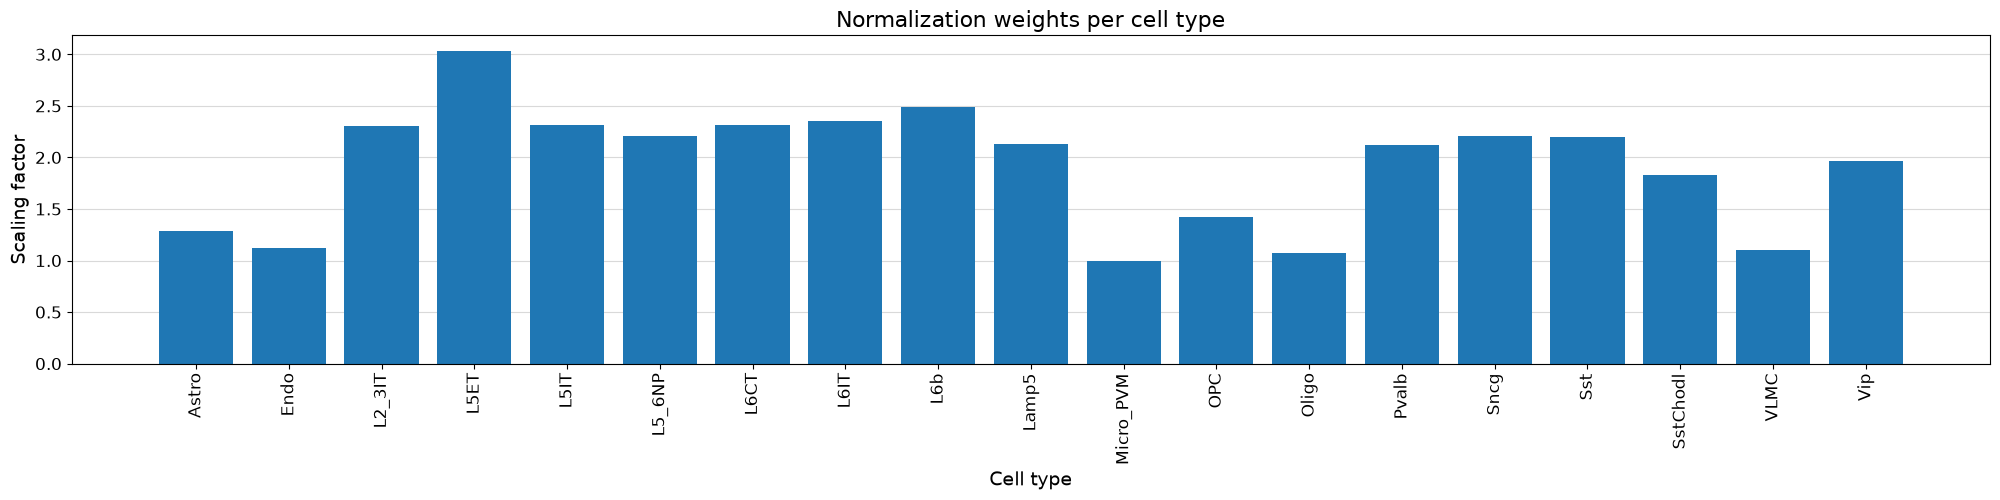

In [9]:
%matplotlib inline
crested.pl.qc.normalization_weights(adata, title="Normalization weights per cell type", xtick_rotation=90)

To get a feeling for our data, we can also look at the self-correlation between classes. If there are certain classes that very strongly anti-correlate with everything else, this can be a sign of low-quality data or strong outliers that might hinder training.

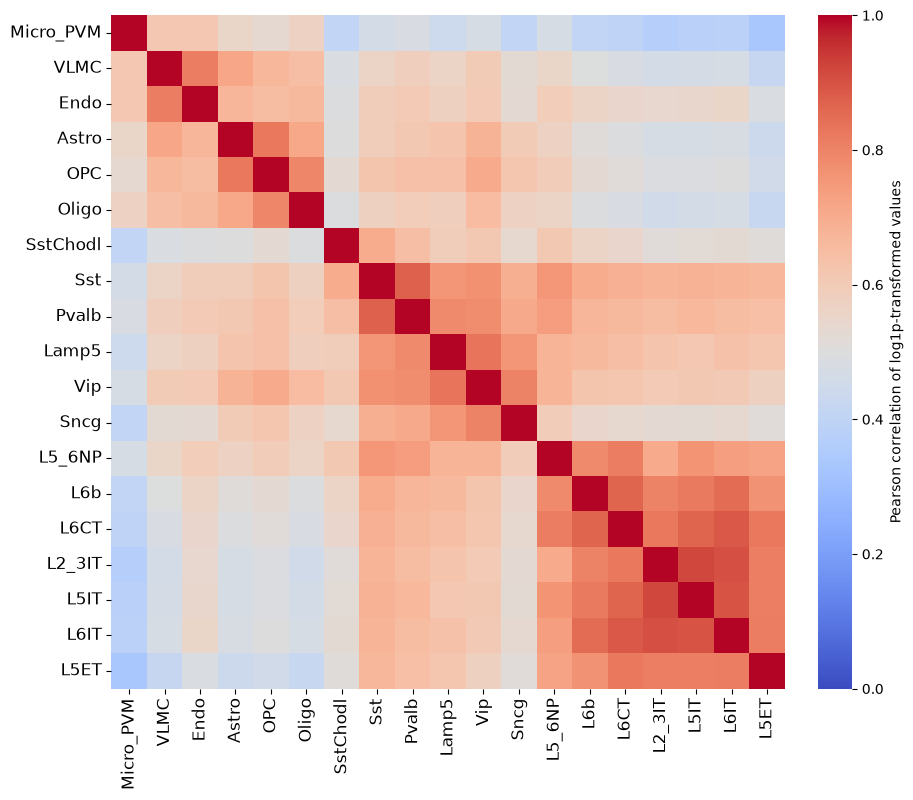

In [10]:
%matplotlib inline
crested.pl.corr.heatmap_self(adata, log_transform=True, vmin=0, vmax=1, reorder=True)

This dataset looks ready to go: there's no crazy outlier classes, and robust differences between the different classes. We do see higher correlations between the profiles of different excitatory neurons, but this is expected biologically.

In [11]:
# Save the final preprocessing results
adata.write_h5ad("./data/mouse_cortex.h5ad", compression="gzip")

## Model training

The CREsted training workflow is built around the {func}`crested.tl.Crested` class.
This class has a couple of required arguments:
- `data`: the {class}`crested.tl.data.AnnDataWrapper` object containing all the data (anndata, genome) and dataloaders that specify how to load the data.
- `model`: the {class}`keras.Model` object containing the model architecture.
- `config`: the {class}`crested.tl.TaskConfig` object containing the optimizer, loss function, and metrics to use in training.  

Since training can take a long time, it's often better to run these steps in a script or a python file, so you could run it on a cluster or in the background.

Just like with the preprocessing, training is also an itertive process. So you can take these as your starting point and improve as needed.

### Data

We'll start by initializing the {class}`crested.tl.data.AnnDataWrapper` object with our data.  
This will tell our model how to load the data and what data to load during fitting/evaluation.
The main arguments to supply are the `adata` object, the `genome` object (if you didn't register one), and the `batch_size`.  
Other optional arguments are related to the training data loading (e.g. shuffling, whether to load the sequences into memory, ...).

In [12]:
datamodule = crested.tl.data.AnnDataWrapper(
    adata,
    batch_size=64,  # lower this if you encounter OOM errors
    max_stochastic_shift=3,  # optional data augmentation to slightly reduce overfitting
    always_reverse_complement=True,  # default True. Will double the effective size of the training dataset.
)

2026-11-04T17:17:30.539275+0100 INFO Lazily importing module crested.tl. This could take a second...
2026-11-04T17:17:31.005810+0100 WARNING modiscolite is not installed, 'crested.tl.modisco' module will not be available. Install with: pip install crested[motif]
2026-11-04T17:17:31.012910+0100 INFO Training split labels inferred to be ['train'].
2026-11-04T17:17:32.920973+0100 INFO Loading sequences into memory...


100%|██████████| 987986/987986 [01:48<00:00, 9091.82it/s]  


### Model definition 

Next, we'll define the model architecture. This is a standard Keras model definition, so you can provide your own model definition if you like.  
Alternatively, there are a couple of ready-to-use models available in the `crested.tl.zoo` module.  
Each of them require the width of the input sequences and the number of output classes (your `adata.obs`) as arguments.

In [13]:
# Load a dilated cnn architecture for a dataset with 2114bp regions and 19 cell types
model = crested.tl.zoo.dilated_cnn(seq_len=2114, num_classes=adata.n_obs)

W0000 00:00:1793809162.304731 2694503 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


### TaskConfig

The TaskConfig object specifies the optimizer, loss function, and metrics to use in training (we call this our 'task').  
Some default configurations are available for some common tasks such as 'topic_classification' and 'peak_regression',
which you can load using the {func}`crested.tl.default_configs` function.  

:::{hint}
If using mean values with {func}`crested.tl.losses.CosineMSELogLoss`, we recommend setting the multiplier to the number of basepairs you're averaging over (your `target_region_width`), which here is 1000. Default config `'peak_regression_mean'` automatically uses `multiplier=1000` for this reason.
:::

Alternatively, you can create your own TaskConfig object and specify the optimizer, loss function, and metrics yourself if you want to do something completely custom.  
Here, we replicate the values from `crested.tl.default_configs("peak_regression_count")` manually:

In [14]:
# Load the default configuration for training a peak regression model on cutsites
config = crested.tl.default_configs("peak_regression_count")  # or "peak_regression_mean"/"topic_classification"

# Or create your own:
# optimizer = keras.optimizers.Adam(learning_rate=1e-3)
# loss = crested.tl.losses.CosineMSELogLoss(max_weight=100, multiplier=1)
# metrics = [
#     keras.metrics.MeanAbsoluteError(),
#     keras.metrics.MeanSquaredError(),
#     keras.metrics.CosineSimilarity(axis=1),
#     crested.tl.metrics.PearsonCorrelation(),
#     crested.tl.metrics.ConcordanceCorrelationCoefficient(),
#     crested.tl.metrics.PearsonCorrelationLog(),
# ]
# config = crested.tl.TaskConfig(optimizer, loss, metrics)

print(config)

TaskConfig(optimizer=<keras.src.optimizers.adam.Adam object at 0x7f4367741010>, loss=CosineMSELogLoss: {'name': 'CosineMSELogLoss', 'reduction': 'sum_over_batch_size', 'max_weight': 100}, metrics=[<MeanAbsoluteError name=mean_absolute_error>, <MeanSquaredError name=mean_squared_error>, <CosineSimilarity name=cosine_similarity>, <PearsonCorrelation name=pearson_correlation>, <ConcordanceCorrelationCoefficient name=concordance_correlation_coefficient>, <PearsonCorrelationLog name=pearson_correlation_log>])


### Training

Now we're ready to train our model (In this tutorial, we will not actually be training the model but use a pretrained model for later steps, but everything you need to train the model is here)
We'll create a {class}`~crested.tl.Crested` object with the data, model, and config objects we just created.  
Then, we can call the {meth}`~crested.tl.Crested.fit` method to train the model.  
Read the documentation for more information on all available arguments to customize your training (e.g. augmentations, early stopping, checkpointing, ...).  

By default: 
1. The model will continue training until the validation loss stops decreasing for 10 epochs with a maximum of 100 epochs.  
2. Every best model is saved based on the validation loss.
3. The learning rate reduces by a factor of 0.25 if the validation loss stops decreasing for 5 epochs.

```{note}
If you specify the same project_name and run_name as a previous run, then CREsted will assume that you want to continue training and will load the last available model checkpoint from the {project_name}/{run_name} folder and continue from that epoch.
```

In [15]:
# setup the trainer
trainer = crested.tl.Crested(
    data=datamodule,
    model=model,
    config=config,
    project_name="mouse_biccn",  # change to your liking
    run_name="base_model",  # change to your liking
    logger="wandb",  # or None, 'dvc', 'tensorboard'
    seed=7,  # For reproducibility
)

2026-11-04T17:19:22.557795+0100 WARNING No GPUs available, falling back to CPU.


In [ ]:
# train the model. we won't actually train it here but you would only need to run this cell to start training.
trainer.fit(
    epochs=60, # you can increase this if the model is still improving after 60 epochs
    learning_rate_reduce_patience=3,
    early_stopping_patience=6,
)

### Finetuning on cell type-specific regions

Differentially accessible regions (DARs) or cell type specific regions are of special interest in scATAC-seq data, as it's a good indicator of potential enhancers. Therefore, here we are fine tuning on these regions to make sure the model performs as well as possible on these regions.

#### Subset the region set

For peak regression models, we recommend to continue training the model trained on all consensus peaks on a subset of cell type-specific regions.
Since we are interested in understanding the enhancer code uniquely identifying the cell types in the dataset, finetuning on specific regions will allow us to approach that.
We define specific regions as regions with a high Gini index, indicating that their peak distribution over all cell types will be skewed and specific for one or more cell types.

Read the documentation of the {func}`crested.pp.filter_regions_on_specificity` function for more information on how the filtering is done. We can check the impact of different cutoffs with {func}`crested.pl.qc.filter_cutoff`:

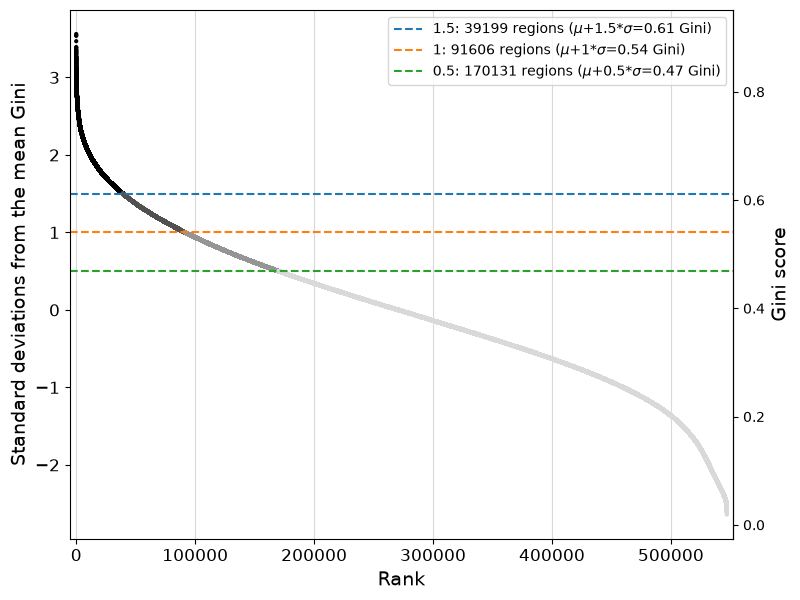

In [16]:
%matplotlib inline
crested.pl.qc.filter_cutoff(adata, cutoffs=[1.5, 1, 0.5], width=8, height=6)

The default `gini_std_threshold` of 1 seems to result in an acceptable set that's both specific and large enough to train on.

In [17]:
# All regions with a Gini index 1 std above the mean across all regions will be kept
adata_specific = crested.pp.filter_regions_on_specificity(adata, gini_std_threshold=1.0, inplace=False)
adata_specific

2026-11-04T17:19:36.019250+0100 INFO After specificity filtering, kept 91606 out of 546993 regions.


AnnData object with n_obs × n_vars = 19 × 91606
    obs: 'file_path'
    var: 'chr', 'start', 'end', 'target_start', 'target_end', 'split', 'unresized_index'
    obsm: 'weights'
    layers: None (.X)

In [18]:
adata_specific.write_h5ad("./data/mouse_cortex_filtered.h5ad")

#### Load the pre-trained model and finetune with a lower learning rate

In [19]:
datamodule = crested.tl.data.AnnDataWrapper(
    adata_specific,
    batch_size=32,  # Recommended to go for a smaller batch size than in the base model
    max_stochastic_shift=3,
    always_reverse_complement=True,
)

2026-11-04T17:20:11.858834+0100 INFO Training split labels inferred to be ['train'].
2026-11-04T17:20:12.141649+0100 INFO Loading sequences into memory...


100%|██████████| 165046/165046 [00:01<00:00, 95138.68it/s] 


In [ ]:
# First load the pre-trained model (we won't actually do it here since we didn't train a model)
# Choose the base model with best validation loss/performance metrics
model = crested.utils.load_model("/PATH/TO/YOUR/MODEL")  # Change this to the path of your base model checkpoint

We use the same config we used for the pretrained model, **except for a lower learning rate**. Make sure that is lower than it was on the epoch you select the model from.

In [20]:
old_config = crested.tl.default_configs("peak_regression_count")
new_optimizer = keras.optimizers.Adam(learning_rate=1e-4)  # Lower LR!
config = crested.tl.TaskConfig(new_optimizer, old_config.loss, old_config.metrics)
print(config)

TaskConfig(optimizer=<keras.src.optimizers.adam.Adam object at 0x7f4366cbc2d0>, loss=CosineMSELogLoss: {'name': 'CosineMSELogLoss', 'reduction': 'sum_over_batch_size', 'max_weight': 100}, metrics=[<MeanAbsoluteError name=mean_absolute_error>, <MeanSquaredError name=mean_squared_error>, <CosineSimilarity name=cosine_similarity>, <PearsonCorrelation name=pearson_correlation>, <ConcordanceCorrelationCoefficient name=concordance_correlation_coefficient>, <PearsonCorrelationLog name=pearson_correlation_log>])


In [21]:
# setup the trainer
trainer = crested.tl.Crested(
    data=datamodule,
    model=model,
    config=config,
    project_name="mouse_biccn",  # change to your liking
    run_name="finetuned_model",  # change to your liking
    logger="wandb",  # or 'wandb', 'tensorboard'
)

2026-11-04T17:20:20.047071+0100 WARNING No GPUs available, falling back to CPU.


In [ ]:
# Same as before, just need to run this cell to start finetuning
trainer.fit(
    epochs=60,
    learning_rate_reduce_patience=3,
    early_stopping_patience=6,
)

## Evaluate the model
Now we have a trained model (we haven't trained a model, so we'll import the model from CREsted model repo), we can use the `crested.tl` toolkit to run inference and explain our results. All the functionality shown below only expects a trained .keras model, meaning that you can use these functions with any model trained outside of the CREsted framework too.

First, we need to load a model. If you followed the tutorial, you can load that one.  
If not, CREsted has a 'model repository' with commonly used models which you can download with 
{func}`~crested.get_model`. You can find all example models [here](/models/index).

In [8]:
# load the DeepBICCN2 model, normally you would load your own model here
# you can use the following command if you haven't downloaded the model yet:
# model_path, output_names = crested.get_model("DeepBICCN2")

model_path = './models/deepbiccn2.tar.gz.untar/deepbiccn2.keras'
output_names = ['Astro', 'Endo', 'L2_3IT', 'L5ET', 'L5IT', 'L5_6NP', 'L6CT', 'L6IT', 'L6b', 'Lamp5',
                'Micro_PVM', 'OPC', 'Oligo', 'Pvalb', 'Sncg', 'Sst', 'SstChodl', 'VLMC', 'Vip']

model = crested.utils.load_model(model_path)

2026-11-05T12:18:31.704469+0100 WARNING modiscolite is not installed, 'crested.tl.modisco' module will not be available. Install with: pip install crested[motif]


I0000 00:00:1793877511.914172 2886529 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 78752 MB memory:  -> device: 0, name: NVIDIA H100 80GB HBM3, pci bus id: 0000:4e:00.0, compute capability: 9.0a


In [9]:
# you can load your data if you are in another session, don't forget to reload the genome as well
adata = ad.read_h5ad("./data/mouse_cortex.h5ad")
adata_specific = ad.read_h5ad("./data/mouse_cortex_filtered.h5ad")

### Predict

{func}`~crested.tl.predict` is CREsted's swiss army knife: it lets you use the model to predict inputs in any form.  
Since CREsted is build around making predictions over genomic sequences, this can accept as input:
- (lists of) sequence(s)
- (lists of) genomic region name(s)
- one hot encoded sequences of shape (N, L, 4)
- AnnData objects with regions as its .var index

CREsted will convert these inputs to its required format for the model.  
If your input is a region name or AnnData, you should provide a genome as well if you did not register one.  
You can even provide a list of models, as long as they expect the same input and output shapes. In that case the predictions will be averaged, which can be useful to make your predictions more robust. 

:::{note}  
Due to issues in `keras`'s prediction functionality, running this for the entire AnnData can use a large amount of memory. If this is a bottleneck, we recommend running this once or in chunks, saving the AnnData with the prediction layers, and restarting the analysis from there.
:::  

Almost all plotting functions recognise predictions saved in the `adata.layers` slot, so we'll be predicting all specific regions and saving the resulting predictions:

In [13]:
predictions = crested.tl.predict(adata_specific, model)
adata_specific.layers["DeepBICCN2"] = predictions.T  # adata expects (classes, genes) instead of (genes, classes)

I0000 00:00:1793877538.086554 2886529 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.
I0000 00:00:1793877538.274064 2887514 service.cc:153] XLA service 0x7f8b24034000 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1793877538.274089 2887514 service.cc:161]   StreamExecutor [0]: NVIDIA H100 80GB HBM3, Compute Capability 9.0a (Driver: 13.1.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1793877538.594846 2887514 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1793877538.907733 2887514 cuda_dnn.cc:461] Loaded cuDNN version 92700
W0000 00:00:1793877541.435507 2887744 hlo_rematerialization.cc:3204] Can't reduce memory use below 59.72GiB (64120128798 bytes) by rematerialization; only reduced to 294.00GiB (315677999152 bytes), down from 294.00GiB (315677999152 bytes) originally
W0000 00:00:1793877553.190105 2887514 b

  9/716 ━━━━━━━━━━━━━━━━━━━━ 11s 16ms/step 

I0000 00:00:1793877571.554491 2887514 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'input_reduce_fusion', 4 bytes spill stores, 4 bytes spill loads

I0000 00:00:1793877571.560957 2887514 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


716/716 ━━━━━━━━━━━━━━━━━━━━ 63s 41ms/step


Many of the plotting functions in the `crested.pl` module can be used to visualize these model predictions.

It's also good to keep in mind that even though a GPU is more or less necessary for training, for inference tasks (especially if you want to investigate specific regions rather than making predictions on everything as we just did) a CPU is more than enough. The time difference for a small set of regions will be managable, so depending on the availability it might be faster to just work with a CPU if there's a long queue on the GPUs. You don't need to change anything in the code, it will automatically detect if there's a GPU and fallback to CPU if it can't find one.

### Evaluating on the test set

Let's first look at the performance on the test set using the {func}`~crested.tl.evaluate` function:

In [14]:
crested.tl.evaluate(
    adata_specific,
    model='DeepBICCN2',
    metrics=crested.tl.default_configs('peak_regression_count')
)

2026-11-05T12:23:57.806215+0100 INFO Test CosineMSELogLoss: -0.6301
2026-11-05T12:23:57.807088+0100 INFO Test mean_absolute_error: 1.6986
2026-11-05T12:23:57.807312+0100 INFO Test mean_squared_error: 14.7285
2026-11-05T12:23:57.807472+0100 INFO Test cosine_similarity: 0.8700
2026-11-05T12:23:57.807640+0100 INFO Test pearson_correlation: 0.7811
2026-11-05T12:23:57.807809+0100 INFO Test concordance_correlation_coefficient: 0.7205
2026-11-05T12:23:57.807966+0100 INFO Test pearson_correlation_log: 0.6337


If you experimented with many different hyperparameters for your model, chances are that you will start overfitting on your validation dataset.  
It's therefore always a good idea to evaluate your model on the test set after getting good results on your validation data to see how well it generalizes to unseen data.

#### Example predictions on test set regions

It is always interesting to see how the model performs on unseen test set regions. It is recommended to always look at a few examples to spot potential biases, or trends that you do not expect.

In [15]:
# Define a dataframe with test set regions
test_df = adata_specific.var[adata_specific.var["split"] == "test"]
test_df

,chr,start,end,target_start,target_end,split,unresized_index
region,,,,,,,
chr18:3269690-3271804,chr18,3269690,3271804,3270247,3271247,test,chr18:3270497-3270997
chr18:3350307-3352421,chr18,3350307,3352421,3350864,3351864,test,chr18:3351114-3351614
chr18:3451398-3453512,chr18,3451398,3453512,3451955,3452955,test,chr18:3452205-3452705
chr18:3463977-3466091,chr18,3463977,3466091,3464534,3465534,test,chr18:3464784-3465284
chr18:3488308-3490422,chr18,3488308,3490422,3488865,3489865,test,chr18:3489115-3489615
...,...,...,...,...,...,...,...
chr9:124125533-124127647,chr9,124125533,124127647,124126090,124127090,test,chr9:124126340-124126840
chr9:124140961-124143075,chr9,124140961,124143075,124141518,124142518,test,chr9:124141768-124142268
chr9:124142793-124144907,chr9,124142793,124144907,124143350,124144350,test,chr9:124143600-124144100


chr18:3892771-3894885
2026-11-05T12:23:58.023607+0100 INFO Lazily importing module crested.pl. This could take a second...


2026-11-05T12:23:58.226893+0100 WARNING modiscolite is not installed, 'crested.pl.modisco' module will not be available. Install with: pip install crested[motif]


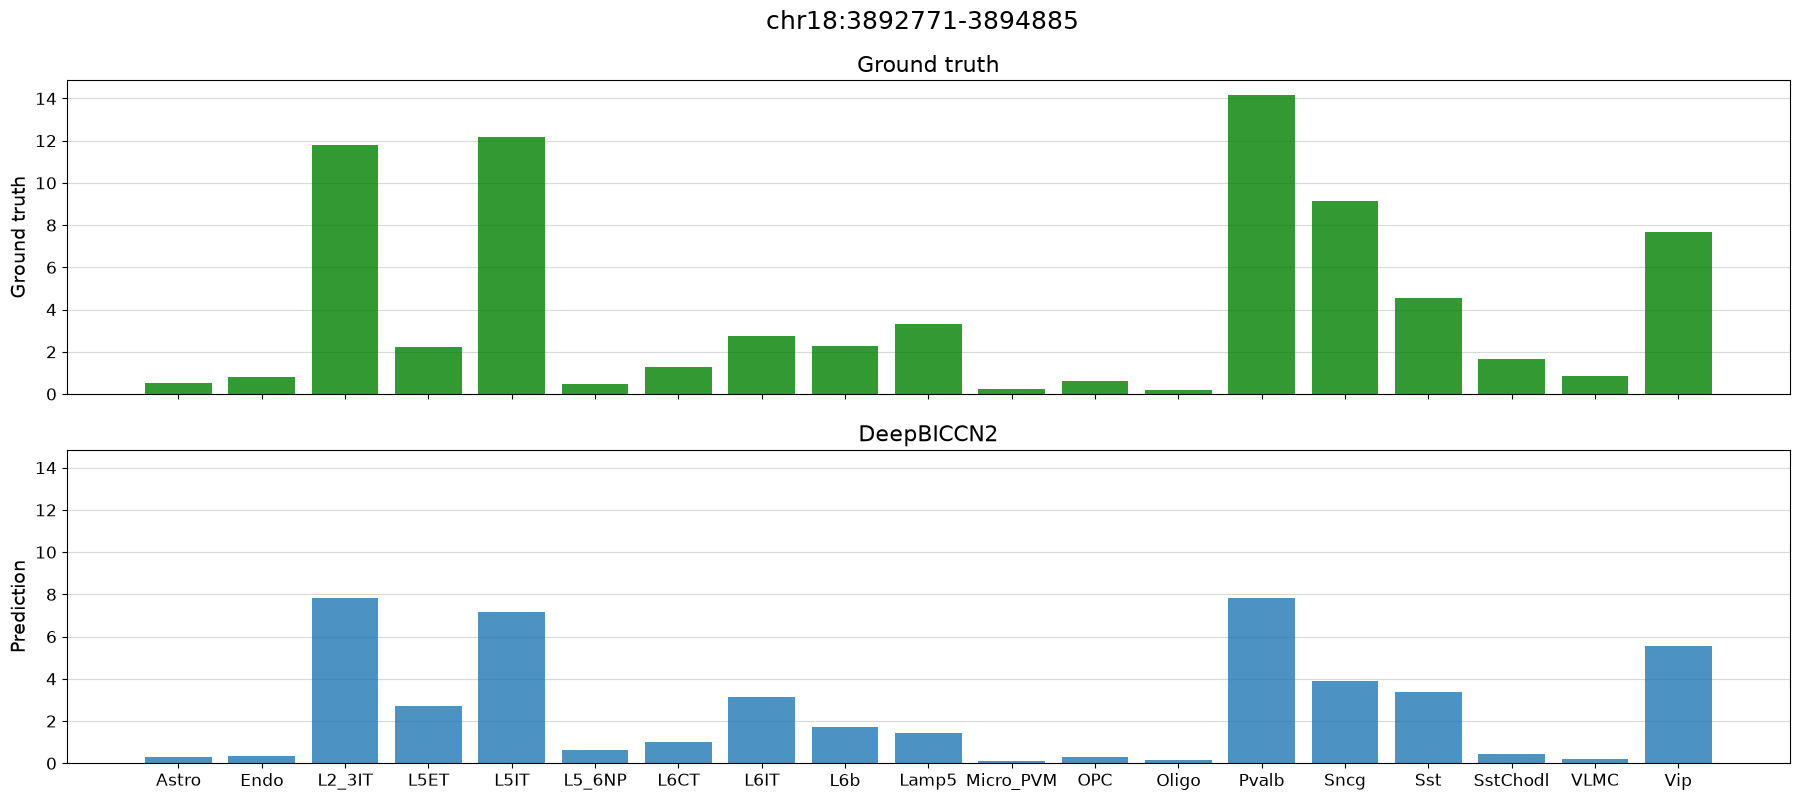

In [16]:
%matplotlib inline
# plot predictions vs ground truth for a random region in the test set defined by index
idx = 21
region = test_df.index[idx]
print(region)
crested.pl.region.bar(adata_specific, region)

##### Example predictions on manually defined regions

1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step


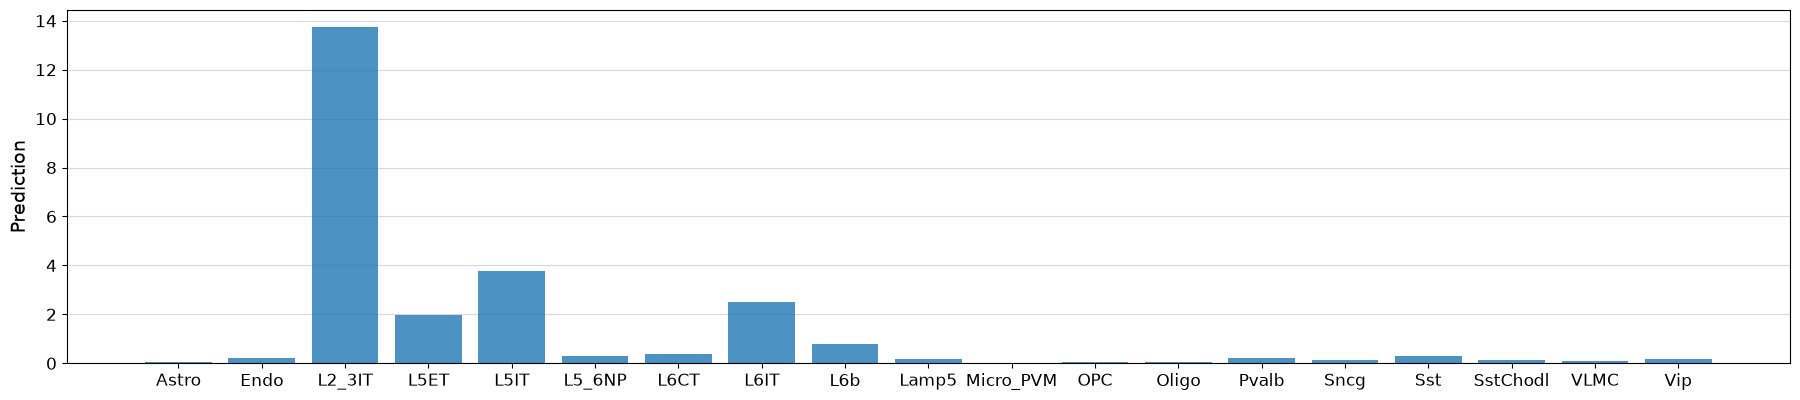

In [17]:
# Could also manually fetch and pass sequence with genome.fetch(chrom, start, end)
prediction = crested.tl.predict("chr3:72535071-72537185", model)

crested.pl.region.bar(prediction, classes=list(adata_specific.obs_names))

#### Model performance on the entire test set

After looking at specific instances, now we can look at the model performance on a larger scale.

First, we can check compare the predictions vs ground truth in a scatterplot for all regions in a class:

2026-11-05T12:24:03.724002+0100 INFO Plotting density scatter for class: L2_3IT, models: ['DeepBICCN2'], split: test


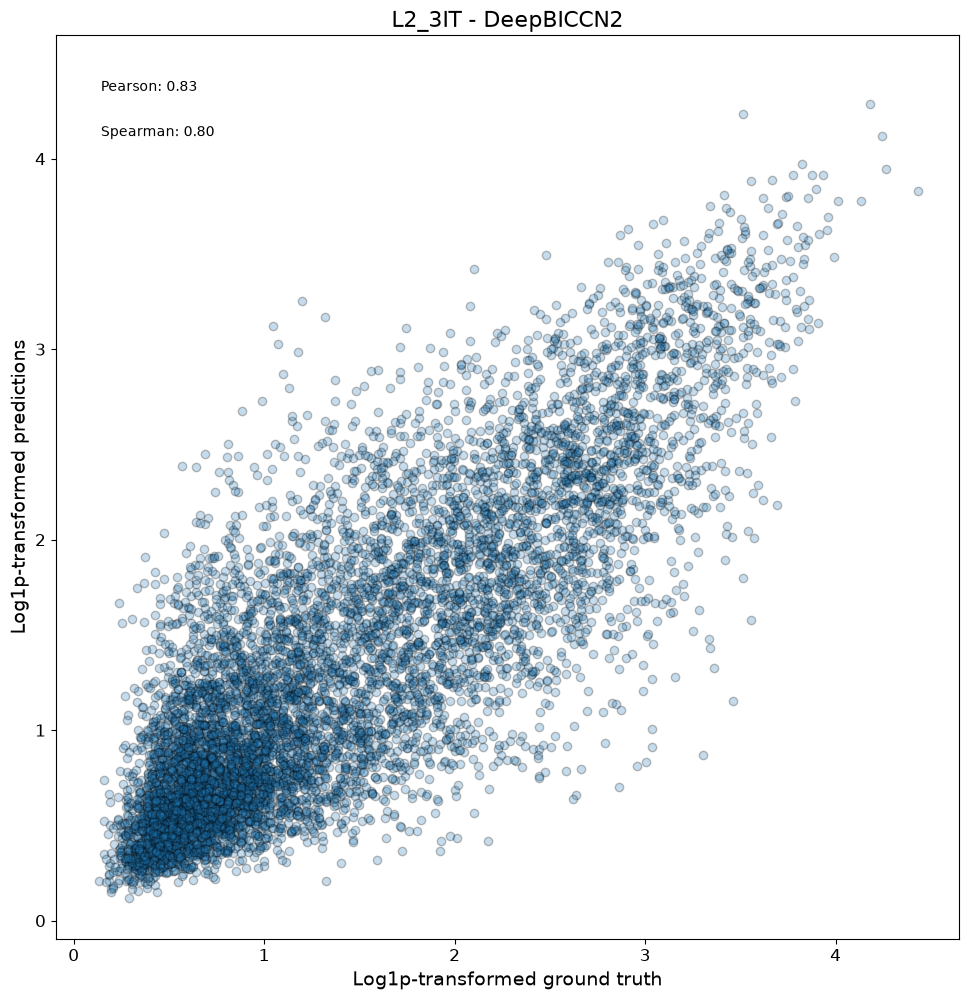

In [18]:
crested.pl.corr.scatter(
    adata_specific,
    class_name="L2_3IT",
    model_names="DeepBICCN2",
    split="test",
    log_transform=True,
    square=True,
    width=10,
    height=10,
)

Or even all classes at once, and/or comparing across models:

2026-11-05T12:24:03.883503+0100 INFO Plotting density scatter for all targets and predictions, models: ['DeepBICCN2'], split: test


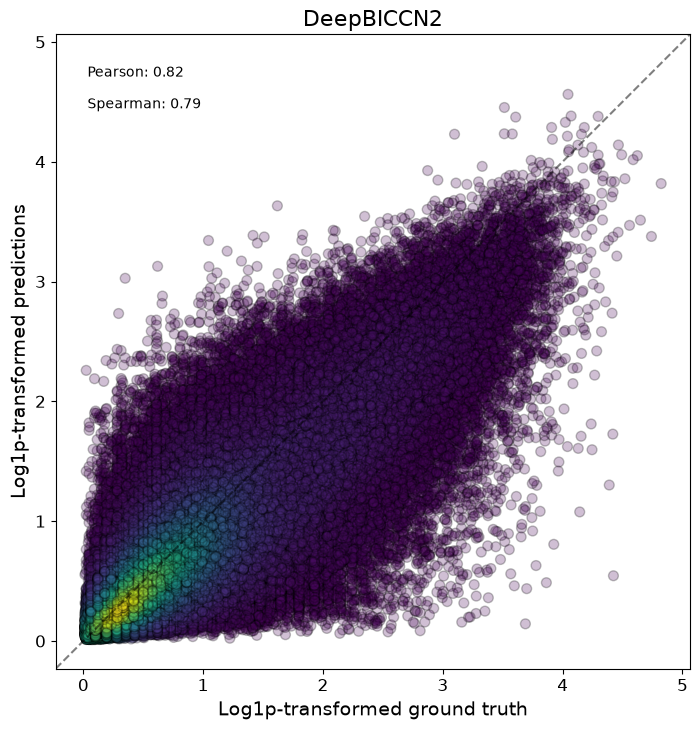

In [19]:
crested.pl.corr.scatter(
    adata_specific,
    split="test",
    model_names="DeepBICCN2",
    log_transform=True,
    density_indication=True,
    identity_line=True,
    square=True,
)

To now check the correlations between all classes, we can plot a heatmap to assess the model performance.

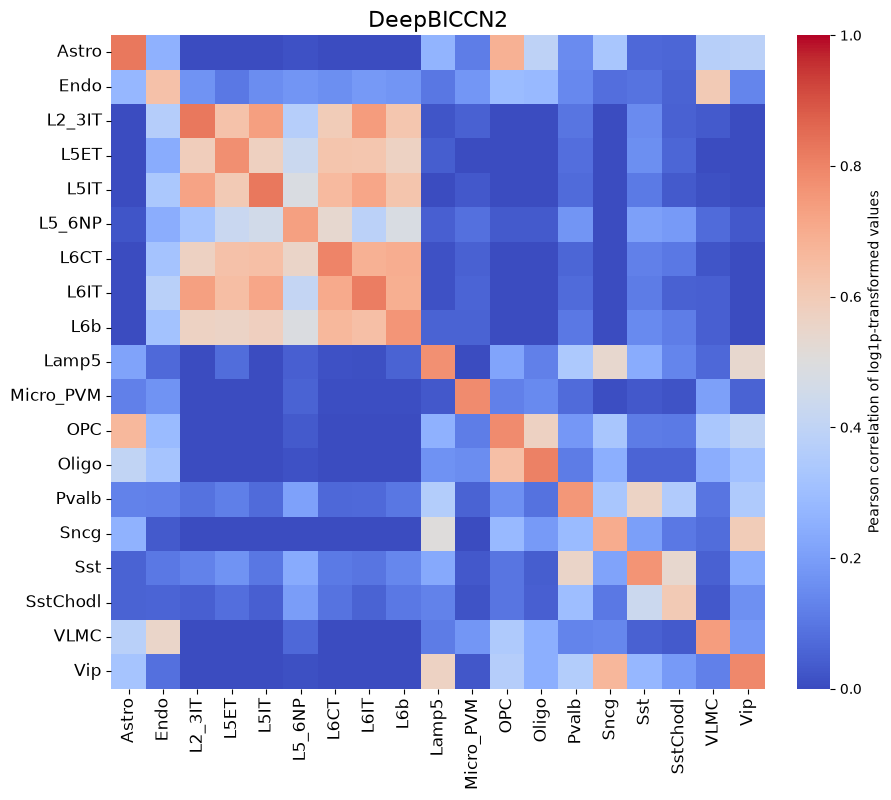

In [20]:
crested.pl.corr.heatmap(
    adata_specific,
    model_names="DeepBICCN2",
    split="test",
    log_transform=True,
    vmax=1,
    vmin=0,
)

It is also recommended to compare this heatmap to the self-correlation plot of the peaks themselves. If peaks between cell types are correlated, then it is expected that predictions from non-matching classes for correlating cell types will also be high, even if the predictions are perfect.

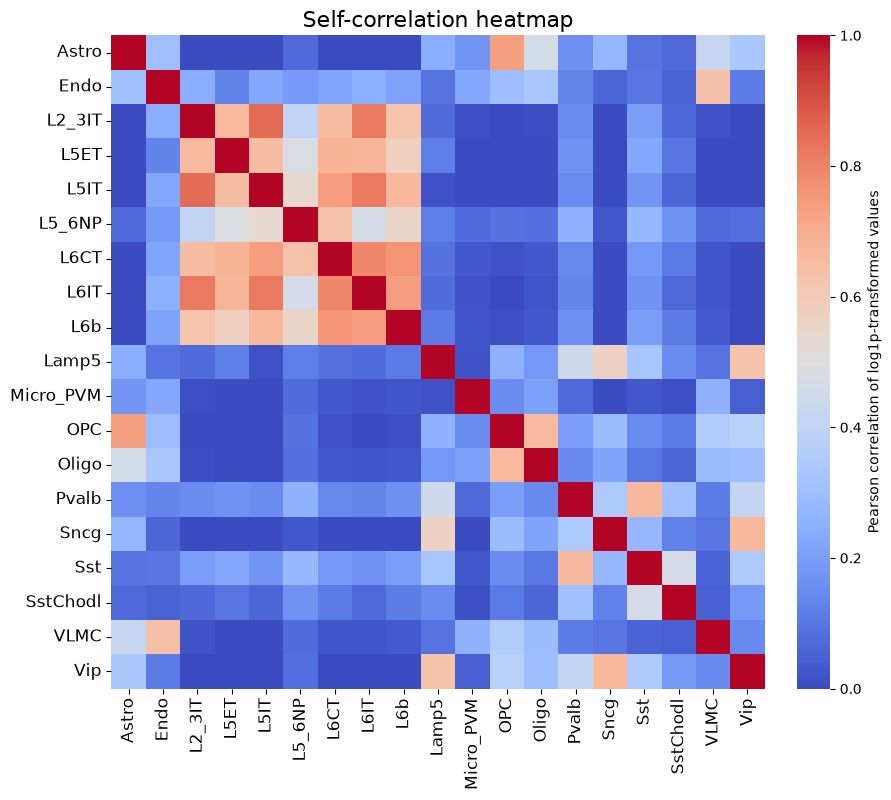

In [21]:
crested.pl.corr.heatmap_self(
    adata_specific,
    xtick_rotation=90,
    log_transform=True,
    title="Self-correlation heatmap",
    vmax=1,
    vmin=0,
)

To better compare different models, we can also specifically compare the correlations for each class with their own ground truths (which are shown on the diagonal in the heatmaps). One way is through a violin plot:

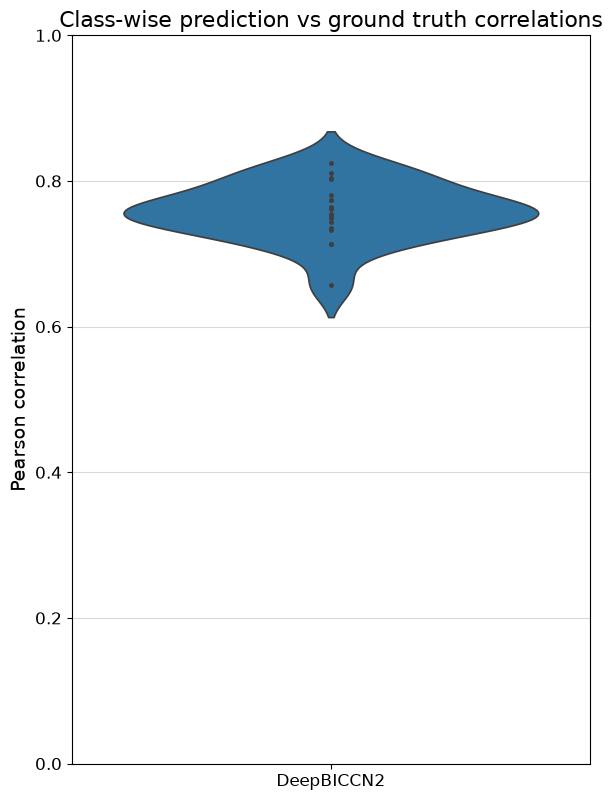

In [22]:
%matplotlib inline
crested.pl.corr.violin(adata_specific)

### Sequence contribution scores

We can calculate the contribution scores for a **sequence** of interest using the {func}`~crested.tl.contribution_scores` function.  

This will give us information on what nucleotides the model is looking at to make its prediction with respect to a specific output class. 

You always need to ensure that the sequence or region you provide is the same length as the model input (2114bp in our case).  

Here, similar to the `predict` function, you need some input (like a sequence or region name) and a (list of) model(s). If multiple models are provided, the contribution scores will be averaged.

#### Contribution scores on manually defined genomic regions

In [23]:
# similar example but with region names as input
regions_of_interest = "chr18:61107770-61109884"  # FIRE enhancer region (Microglia enhancer)
classes_of_interest = ["Astro", "Micro_PVM"]
class_idx = list(adata_specific.obs_names.get_indexer(classes_of_interest))

scores, one_hot_encoded_sequences = crested.tl.contribution_scores(
    regions_of_interest,
    target_idx=class_idx,
    model=model,
    method="integrated_grad", # recommended. Other options: "expected_integrated_grad" (default), "saliency_map", "mutagenesis", "window_shuffle"
)

2026-11-05T12:24:48.316375+0100 INFO Calculating contribution scores for 1 region(s) and 2 class(es).


Model: 100%|██████████| 1/1 [00:08<00:00,  8.18s/it]


Contribution scores for regions can be plotted using the {func}`crested.pl.explain.contribution_scores` function.  
This will generate a subplot per region, per class.

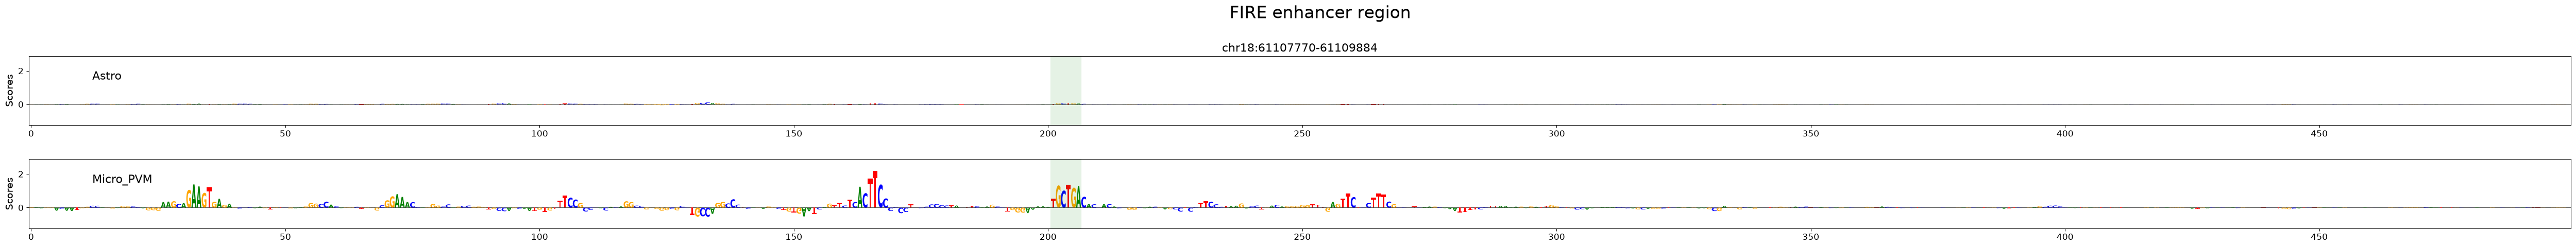

In [24]:
%matplotlib inline
crested.pl.explain.contribution_scores(
    scores,
    one_hot_encoded_sequences,
    sequence_labels=regions_of_interest,
    class_labels=classes_of_interest,
    zoom_n_bases=500,
    suptitle="FIRE enhancer region",
    suptitle_fontsize=24,
    highlight_positions=(1008, 1014),  # starts counting from start of region, not from zoom
    highlight_kws={'facecolor': 'green', 'edgecolor': 'green', 'alpha': 0.1},
)

#### Contribution scores on random test set regions

In [25]:
# plot predictions vs ground truth for a random region in the test set defined by index
idx = 21
region = test_df.index[idx]
classes_of_interest = ["L2_3IT", "Pvalb"]
class_idx = list(adata_specific.obs_names.get_indexer(classes_of_interest))
scores, one_hot_encoded_sequences = crested.tl.contribution_scores(
    region,
    target_idx=class_idx,
    model=model,
    method='integrated_grad',
)

2026-11-05T12:24:59.913154+0100 INFO Calculating contribution scores for 1 region(s) and 2 class(es).


Model: 100%|██████████| 1/1 [00:00<00:00, 11.79it/s]


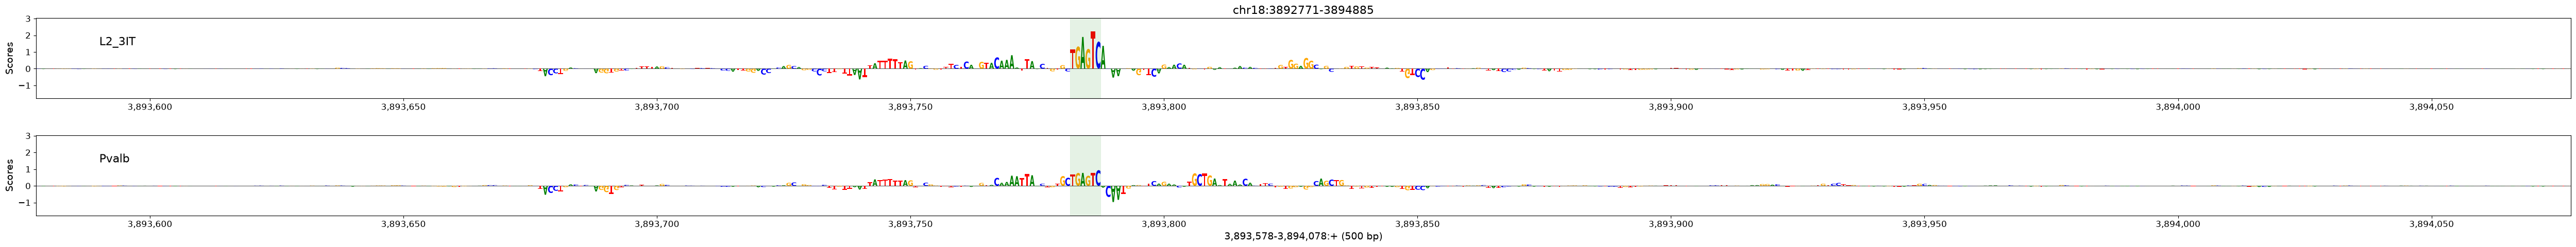

In [26]:
crested.pl.explain.contribution_scores(
    scores,
    one_hot_encoded_sequences,
    sequence_labels=region,
    class_labels=classes_of_interest,
    zoom_n_bases=500,
    coordinates=region,
    highlight_positions=(3893782, 3893788),
    highlight_kws={'facecolor': 'green', 'edgecolor': 'green', 'alpha': 0.1}
)

#### Prediction on gene locus

We can also score a gene locus by using a sliding window over a predefined genomic range. We can then compare those predictions to the bigWig of the cell type where we got our peak scores from, to see if the CREsted predictions match the measured data. 

In [27]:
chrom = "chr18"  # Unseen chromosome
start = 59175401
end = 59410446

cell_type = "L6CT"
class_idx = list(adata_specific.obs_names).index(cell_type)

upstream = 50000
downstream = 25000

strand = "+"

scores, coordinates, min_loc, max_loc, tss_position = crested.tl.score_gene_locus(
    chr_name=chrom,
    gene_start=start,
    gene_end=end,
    target_idx=class_idx,
    model=model,
    strand=strand,
    upstream=upstream,
    downstream=downstream,
    step_size=100,
)

25/25 ━━━━━━━━━━━━━━━━━━━━ 8s 324ms/step


In [30]:
bigwig = os.path.join(bigwigs_folder, f"{cell_type}.bw")

values = (
    crested.utils.read_bigwig_region(bigwig, (chrom, start - upstream, end + downstream))
    if strand == "+"
    else crested.utils.read_bigwig_region(bigwig, (chrom, start - downstream, end + upstream))
)
bw_values = values[0]
midpoints = values[1]

Note that here we compared pooled predictions over 1kb regions and cut-sites at 1 bp resolution from a cut-sites BigWig. To get a better comparison between the predicted and scATAC track, we recommend to compare against a coverage BigWig.

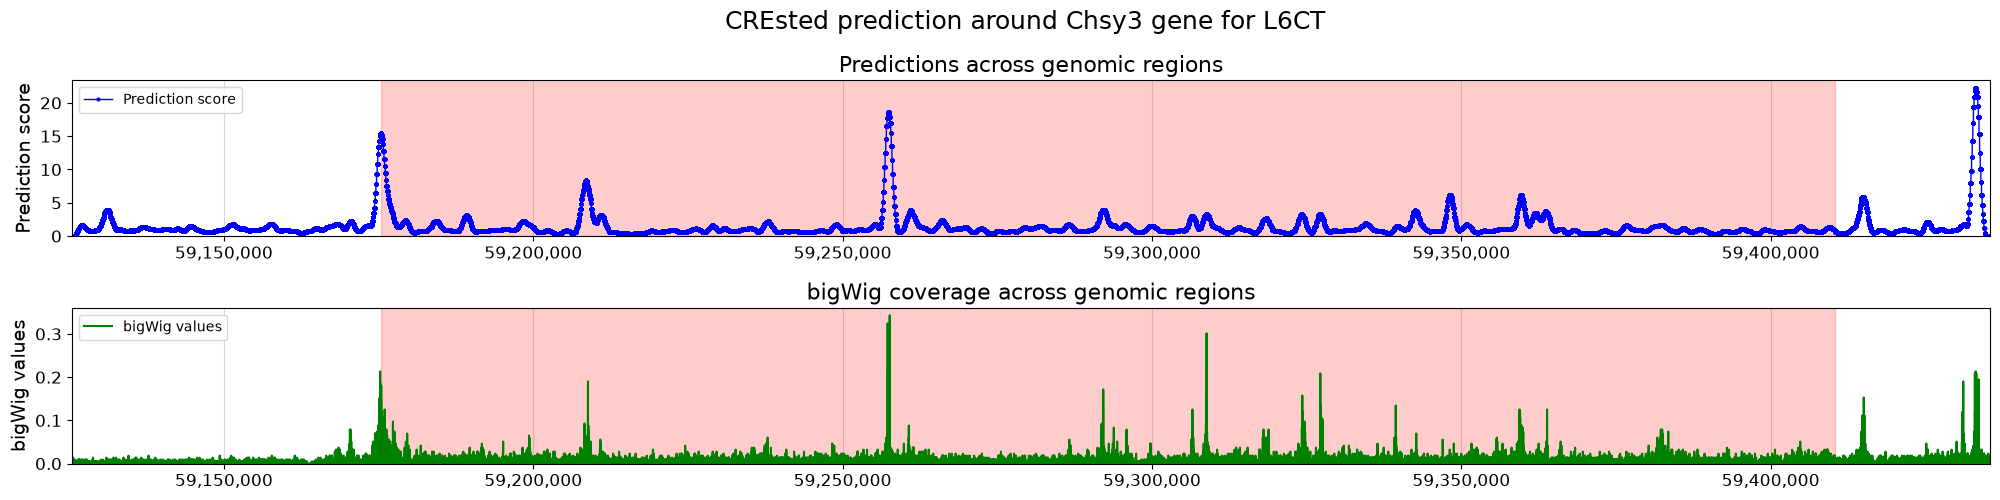

In [31]:
%matplotlib inline
crested.pl.locus.locus_scoring(
    scores,
    (min_loc, max_loc),
    gene_start=start,
    gene_end=end,
    suptitle="CREsted prediction around Chsy3 gene for " + cell_type,
    bigwig_values=bw_values,
    bigwig_midpoints=midpoints,
    grid='x',
    width=20,
    height=5,
    locus_plot_kws={'markersize': 2, 'linewidth': 1},
)

So this is how you train, evaluate and use a sequence-to-function model on your scATAC-seq data. The things that you can do with these models are really limitless. Please do try to give it a shot! Also, this topic has been quite popular for some years, therefore there are a lot of public models available. First place to check would be the CREsted model repo, and after checking the literature for published models. If you can find a public model that suits your questions, using them are much less resource intensive than training your own models!